# Assignment 9

Local binary pattern, then denoising of Gaussian noise and speckle noise.

Sample: `sample_portrait.jpg`. The face has texture for the LBP, and smooth skin so the filters can be compared. Window is 5x5. The last figure zooms in on the eyes.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# local binary pattern, then denoise gaussian noise and speckle noise
# filters: wiener, median, gaussian, bilateral. window is 3x3 or 5x5

np.random.seed(3)

GAUSS_VAR = 0.01     # imnoise default
SPECKLE_VAR = 0.04   # imnoise speckle default


def local_binary_pattern(img):
    # 8 neighbours, clockwise, starting at the top-left
    g = img.astype(np.int16)
    p = np.pad(g, 1, mode="edge")
    h, w = g.shape
    centre = p[1:h + 1, 1:w + 1]
    offsets = [(-1, -1), (-1, 0), (-1, 1), (0, 1),
               (1, 1), (1, 0), (1, -1), (0, -1)]
    code = np.zeros((h, w), dtype=np.int16)
    for bit, (dy, dx) in enumerate(offsets):
        nb = p[1 + dy:h + 1 + dy, 1 + dx:w + 1 + dx]
        code += (nb >= centre).astype(np.int16) << bit
    return code.astype(np.uint8)


def wiener_filter(img, k):
    # local mean and local variance, noise variance = average local variance
    src = img.astype(np.float64)
    mean = cv2.blur(src, (k, k))
    mean_sq = cv2.blur(src * src, (k, k))
    var = mean_sq - mean * mean
    var = np.maximum(var, 0)
    noise = float(np.mean(var))

    out = mean.copy()
    mask = var > noise
    # f = m + (v - noise) / v * (g - m)
    out[mask] = mean[mask] + ((var[mask] - noise) / var[mask]) * (src[mask] - mean[mask])
    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10((255.0 ** 2) / mse)


def add_gaussian(img, var):
    f = img.astype(np.float64) / 255.0
    n = np.random.normal(0.0, np.sqrt(var), img.shape)
    out = np.clip(f + n, 0, 1)
    return np.clip(np.round(out * 255), 0, 255).astype(np.uint8)


def add_speckle(img, var):
    # imnoise speckle: J = I + n*I, n uniform with mean 0 and variance v
    f = img.astype(np.float64) / 255.0
    n = np.sqrt(12.0 * var) * (np.random.rand(*img.shape) - 0.5)
    out = np.clip(f + f * n, 0, 1)
    return np.clip(np.round(out * 255), 0, 255).astype(np.uint8)


def denoise_all(noisy, k):
    # bilateral sigma is in gray levels / pixels. these are fine for 8-bit
    if k == 3:
        sig_c, sig_s = 35, 35
    else:
        sig_c, sig_s = 75, 75

    results = [
        ("Wiener", wiener_filter(noisy, k)),
        ("Median", cv2.medianBlur(noisy, k)),
        ("Gaussian", cv2.GaussianBlur(noisy, (k, k), 0)),
        ("Bilateral", cv2.bilateralFilter(noisy, k, sig_c, sig_s)),
    ]
    return results, sig_c, sig_s


def show_row(img, noisy, results, heading):
    pics = [("Original", img), ("Noisy", noisy)] + results
    plt.figure(figsize=(12, 3.2))
    for i, (name, pic) in enumerate(pics):
        plt.subplot(1, len(pics), i + 1)
        plt.imshow(pic, cmap="gray", vmin=0, vmax=255)
        plt.title(name)
        plt.axis("off")
    plt.suptitle(heading)
    plt.tight_layout()


def report(img, noisy, results, label):
    print(label)
    print("  noisy PSNR     ", round(psnr(img, noisy), 2), "dB")
    for name, pic in results:
        print(f"  {name:10} PSNR {psnr(img, pic):6.2f} dB")


sample image: sample_portrait.jpg (256, 256)
window 5x5
gaussian variance 0.01 , speckle variance 0.04
bilateral sigmaColor = 75  sigmaSpace = 75
Gaussian noise
  noisy PSNR      20.41 dB
  Wiener     PSNR  29.52 dB
  Median     PSNR  30.27 dB
  Gaussian   PSNR  30.18 dB
  Bilateral  PSNR  29.64 dB
Speckle noise
  noisy PSNR      19.22 dB
  Wiener     PSNR  27.41 dB
  Median     PSNR  27.52 dB
  Gaussian   PSNR  28.72 dB
  Bilateral  PSNR  27.45 dB


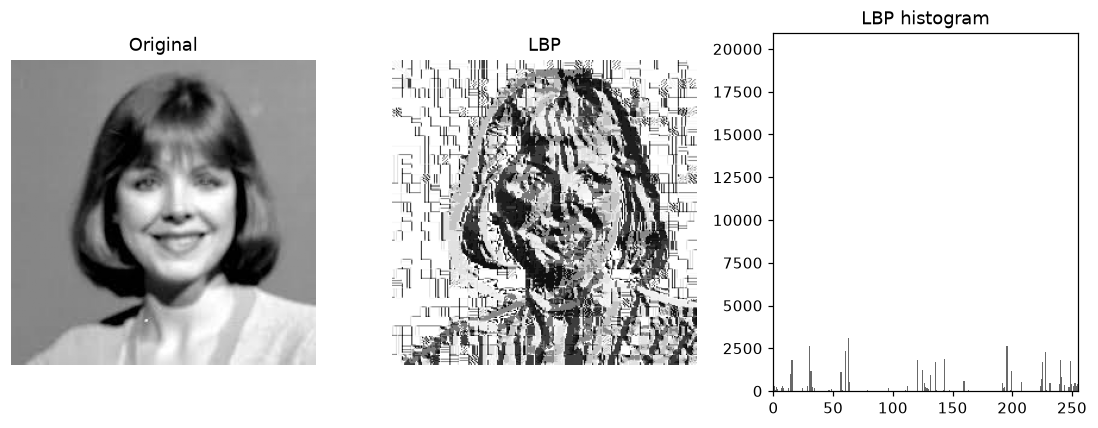

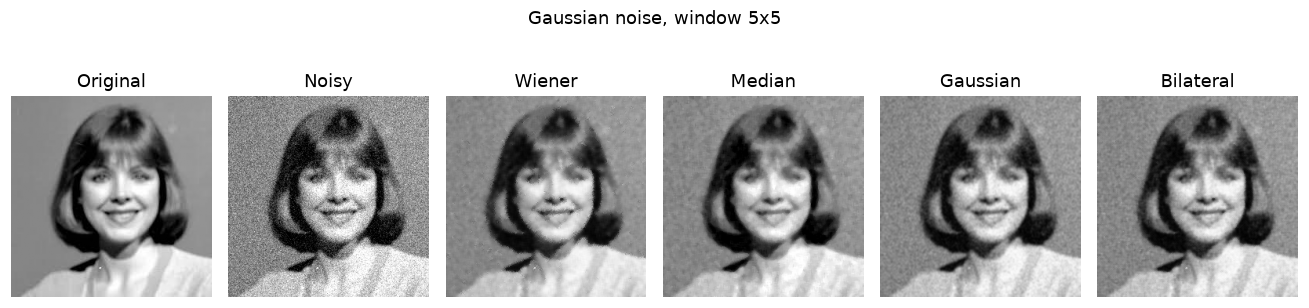

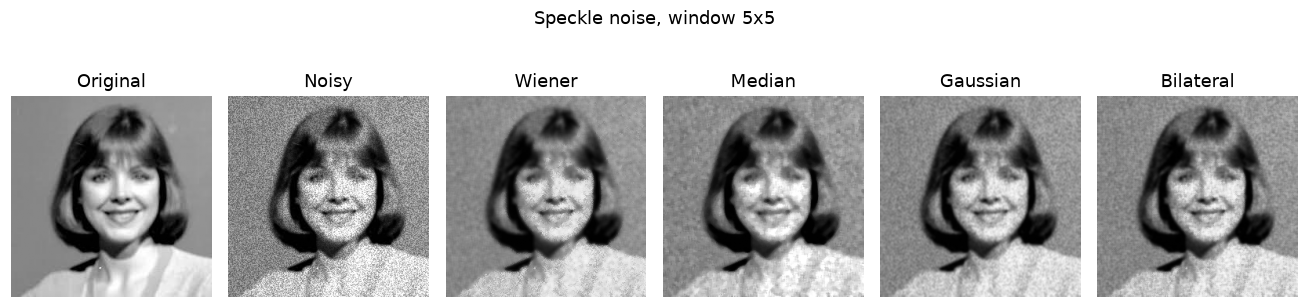

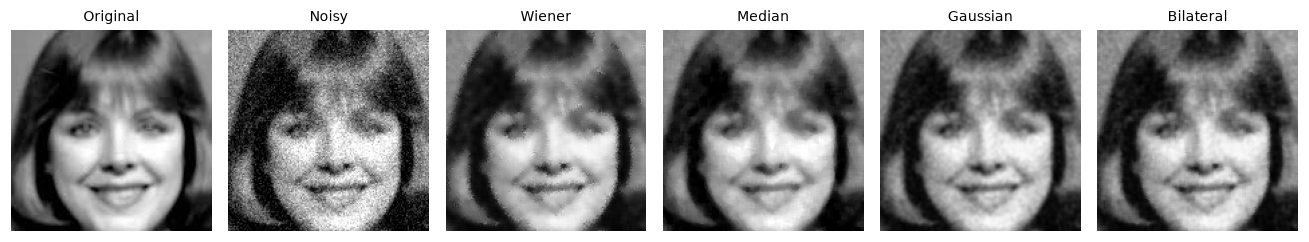

In [2]:
image_path = "sample_portrait.jpg"
k = 5

img = cv2.imread(image_path, 0)
print("sample image:", image_path, img.shape)
print("window", str(k) + "x" + str(k))

lbp = local_binary_pattern(img)
g_noisy = add_gaussian(img, GAUSS_VAR)
s_noisy = add_speckle(img, SPECKLE_VAR)
g_out, sig_c, sig_s = denoise_all(g_noisy, k)
s_out, _, _ = denoise_all(s_noisy, k)

print("gaussian variance", GAUSS_VAR, ", speckle variance", SPECKLE_VAR)
print("bilateral sigmaColor =", sig_c, " sigmaSpace =", sig_s)
report(img, g_noisy, g_out, "Gaussian noise")
report(img, s_noisy, s_out, "Speckle noise")

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(lbp, cmap="gray", vmin=0, vmax=255)
plt.title("LBP")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.hist(lbp.ravel(), bins=256, range=(0, 256), color="dimgray")
plt.title("LBP histogram")
plt.xlim(0, 255)
plt.tight_layout()

show_row(img, g_noisy, g_out, "Gaussian noise, window " + str(k) + "x" + str(k))
show_row(img, s_noisy, s_out, "Speckle noise, window " + str(k) + "x" + str(k))

# zoom so the eyes show which filter keeps the detail
y0, x0, side = 30, 60, 150
zoom = [("Original", img), ("Noisy", g_noisy)] + g_out
plt.figure(figsize=(12, 2.8))
for i, (name, pic) in enumerate(zoom):
    plt.subplot(1, len(zoom), i + 1)
    plt.imshow(pic[y0:y0 + side, x0:x0 + side], cmap="gray", vmin=0, vmax=255)
    plt.title(name, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()
